# Atividade 1- Semana 9 - Python para finanças - Carteira de Ações

Olá,

O objetivo deste exercício é calcular a taxa de retorno e também gerar o gráfico comparando a carteira **(acoes_ex)** com o índice IBOVESPA.
Você pode seguir exatamente o mesmo código implementado na aula.
Bom trabalho!



## 1. Importação das bibliotecas e da base de dados


In [3]:
import pandas as pd
import numpy as np
import plotly.express as px

In [4]:
dataset = pd.read_csv('/home/mgabriel4/Documentos/GitHub/python-investimentos/bases/acoes_ex.csv')
dataset['Date'] = pd.to_datetime(dataset['Date'])
dataset.head()

,Date,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA
0,2015-01-02,16.020000,9.37,37.820000,9.00,22.650000,47.259998
1,2015-01-05,15.730000,9.62,37.070000,8.27,22.180000,46.320000
2,2015-01-06,16.330000,9.55,36.150002,8.06,22.490000,46.580002
3,2015-01-07,16.559999,9.69,37.389999,8.45,23.480000,48.150002
4,2015-01-08,16.540001,9.66,38.910000,9.02,23.559999,48.509998


## 2. Normalização dos preços

Dividimos cada preço pelo primeiro preço da respectiva ação. Dessa forma, todas as séries começam em 1, facilitando a comparação do desempenho.

In [5]:
dataset_normalizado = dataset.copy()

for i in dataset_normalizado.columns[1:]:
    dataset_normalizado[i] = dataset_normalizado[i] / dataset_normalizado[i].iloc[0]

dataset_normalizado.head()

,Date,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA
0,2015-01-02,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,2015-01-05,0.981898,1.026681,0.980169,0.918889,0.979249,0.980110
2,2015-01-06,1.019351,1.019210,0.955844,0.895556,0.992936,0.985612
3,2015-01-07,1.033708,1.034152,0.988630,0.938889,1.036645,1.018832
4,2015-01-08,1.032459,1.030950,1.028821,1.002222,1.040177,1.026449


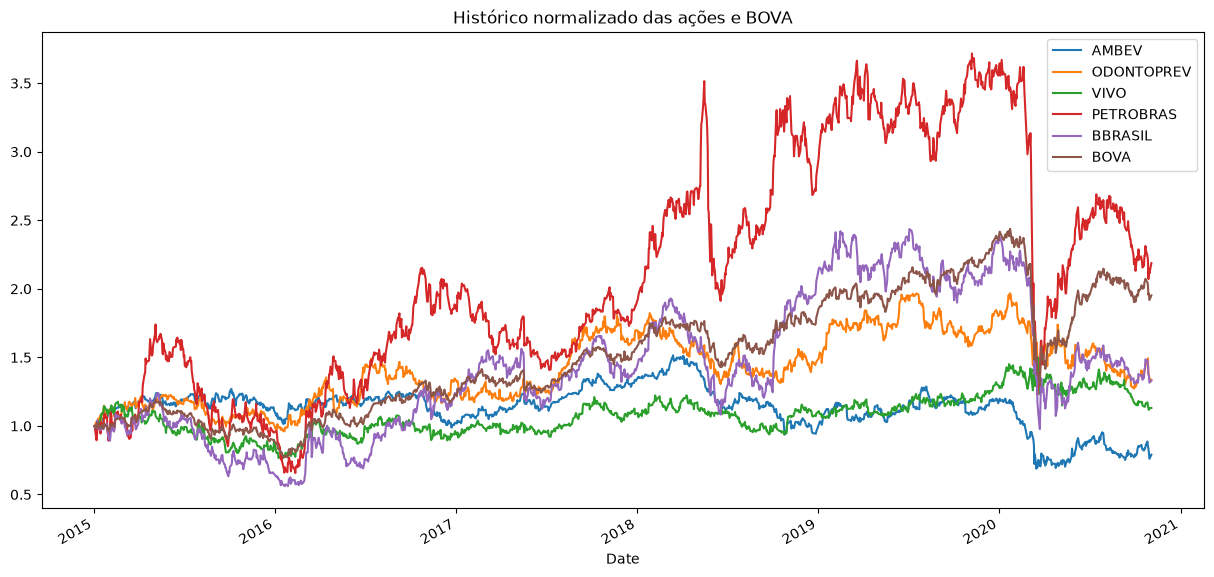

In [6]:
dataset_normalizado.plot(x='Date', figsize=(15, 7), title='Histórico normalizado das ações e BOVA');

## 3. Taxa de retorno da carteira

O retorno diário simples corresponde a `(preço atual / preço anterior) - 1`. Calculamos a média diária, multiplicamos por 246 pregões e por 100 para obter o retorno médio anualizado em porcentagem.

In [7]:
precos_normalizados = dataset_normalizado.drop(labels=['Date'], axis=1)
retorno_carteira = (precos_normalizados / precos_normalizados.shift(1)) - 1
retorno_carteira.head()

,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA
0,NaN,NaN,NaN,NaN,NaN,NaN
1,-0.018102,0.026681,-0.019831,-0.081111,-0.020751,-0.019890
2,0.038144,-0.007276,-0.024818,-0.025393,0.013977,0.005613
3,0.014084,0.014660,0.034301,0.048387,0.044020,0.033705
4,-0.001208,-0.003096,0.040653,0.067456,0.003407,0.007477


In [8]:
retorno_anual = retorno_carteira.mean() * 246
retorno_anual = retorno_anual * 100
retorno_anual.round(2)

AMBEV         -0.31
ODONTOPREV     9.84
VIVO           7.20
PETROBRAS     27.64
BBRASIL       15.97
BOVA          15.11
dtype: float64

### Pesos da carteira

Distribuímos o investimento igualmente entre as cinco ações (20% para cada uma). O peso do BOVA é zero, porque ele será usado apenas como referência.

In [9]:
pesos_carteira = np.array([0.2, 0.2, 0.2, 0.2, 0.2, 0.0])
print(f'Soma dos pesos da carteira: {pesos_carteira.sum():.2f}')
print('Ordem dos ativos:', list(precos_normalizados.columns))
assert list(precos_normalizados.columns) == ['AMBEV', 'ODONTOPREV', 'VIVO', 'PETROBRAS', 'BBRASIL', 'BOVA'], 'Confira a ordem das colunas antes de aplicar os pesos.'

Soma dos pesos da carteira: 1.00
Ordem dos ativos: ['AMBEV', 'ODONTOPREV', 'VIVO', 'PETROBRAS', 'BBRASIL', 'BOVA']


In [10]:
retorno_medio_anualizado = np.dot(retorno_anual, pesos_carteira)
print(f'O retorno médio anualizado da carteira é: {retorno_medio_anualizado:.2f}%')
print(f'O retorno médio anualizado do BOVA é: {retorno_anual["BOVA"]:.2f}%')

O retorno médio anualizado da carteira é: 12.07%
O retorno médio anualizado do BOVA é: 15.11%


## 4. Gráfico da carteira x BOVA

Como no exemplo da aula, a série `CARTEIRA` é a média dos valores normalizados das cinco ações. Ela representa uma composição igualmente ponderada para comparar a evolução com o BOVA.

In [11]:
dataset_normalizado['CARTEIRA'] = (
    dataset_normalizado['AMBEV'] + dataset_normalizado['ODONTOPREV'] +
    dataset_normalizado['VIVO'] + dataset_normalizado['PETROBRAS'] +
    dataset_normalizado['BBRASIL']
) / 5
dataset_normalizado.head()

,Date,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA,CARTEIRA
0,2015-01-02,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,2015-01-05,0.981898,1.026681,0.980169,0.918889,0.979249,0.980110,0.977377
2,2015-01-06,1.019351,1.019210,0.955844,0.895556,0.992936,0.985612,0.976579
3,2015-01-07,1.033708,1.034152,0.988630,0.938889,1.036645,1.018832,1.006405
4,2015-01-08,1.032459,1.030950,1.028821,1.002222,1.040177,1.026449,1.026926


In [12]:
figura = px.line(title='Comparativo individual + carteira x BOVA')
for i in dataset_normalizado.columns[1:]:
    figura.add_scatter(x=dataset_normalizado['Date'], y=dataset_normalizado[i], name=i)
figura.update_layout(xaxis_title='Data', yaxis_title='Preço normalizado')
figura.show()

In [13]:
comparativo = dataset_normalizado.drop(['AMBEV', 'ODONTOPREV', 'VIVO', 'PETROBRAS', 'BBRASIL'], axis=1)
figura = px.line(title='Comparativo da carteira x BOVA')
for i in comparativo.columns[1:]:
    figura.add_scatter(x=comparativo['Date'], y=comparativo[i], name=i)
figura.update_layout(xaxis_title='Data', yaxis_title='Preço normalizado')
figura.show()

## 5. Conclusão

A taxa de retorno médio anualizado da carteira foi calculada pela média dos retornos simples diários de cada ativo, multiplicada por 246 pregões e ponderada pelos pesos de 20% atribuídos a cada ação, utilizando `np.dot()`. O gráfico compara a evolução normalizada dessa carteira com o BOVA, referência do Ibovespa. Valores acima de 1 representam valorização em relação ao preço inicial, e abaixo de 1 representam desvalorização.

**Observação:** o cálculo anualizado é uma estimativa baseada na média diária; não é a rentabilidade efetivamente realizada em um ano. Como o arquivo `acoes_ex.csv` não acompanhou os anexos desta mensagem, os valores numéricos e o gráfico serão gerados ao executar o notebook com esse CSV.